In [2]:
# DecisionTreeClassifier를 활용한 분류 모델 생성
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 데이터셋 준비
iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# criterion="gini" 와 splitter="best"는 디폴트값이다.
model = DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    random_state=42
)

# fit() : 최적의 분할 조건을 탐색하며 노드 트리 생성
model.fit(X_train, y_train)

# predict() : 생성된 노드 트리 조건을 따라 이동하며 클래스 예측
y_pred = model.predict(X_test)

# 모델 성능 평가
test_accuracy = accuracy_score(y_test, y_pred)
print(test_accuracy)

0.9333333333333333


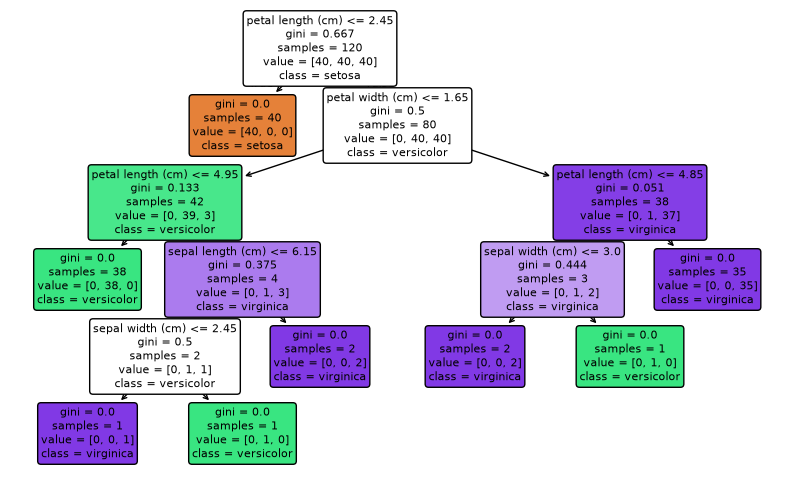

In [ ]:
# Decision Tree 시각화
# scikit-learn의 plot_tree()를 활용하면 학습된 트리를 시각화 할 수 있다.
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(10, 6))

# model : 학습된 Decision Tree 모델 생성
# feature_names : Feature 이름 표시
# class_names : Class 이름 표시
# filled : 클래스에 따라 노드 색상 표시
# rounded : 노드 모서리를 둥글게 표시
plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.show()

#### ✅ 노드 구조 해석
- `petal length <= 2.45` : 분할 조건
- `gini = 0.667` : 노드의 불순도
- `samples = 120` : 노드의 데이터 개수
- `value = [40, 40, 40]` : 클래스별 데이터 개수
- `class = setosa` : 예측 클래스

In [ ]:
# 트리 구조 확인
print("Tree Depth :", model.get_depth())
print("Node Count :", model.tree_.node_count)
print("Leaf Count :", model.get_n_leaves())

Tree Depth : 5
Node Count : 15
Leaf Count : 8


---
#### 실습 문제

학습 데이터 정확도 : 1.0
테스트 데이터 정확도 : 0.9444444444444444


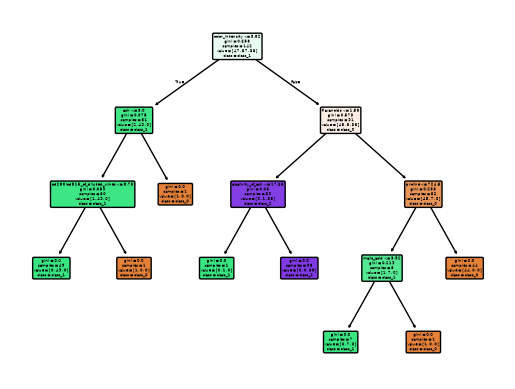

트리의 깊이 : 4
전체 노드 개수 : 15
Leaf Node 개수 : 8
Gini 모델 정확도 : 0.9444444444444444
Entropy 모델 정확도 : 0.9722222222222222
Gini 모델 깊이 : 4
Entropy 모델 깊이 : 4


In [11]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

wine = load_wine()

X = wine.data
y = wine.target

# 1. 학습 데이터 80%, 테스트 데이터 20%로 분리하기 (random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 2. Gini를 사용하는 Decision Tree 모델 생성하기
gini_model = DecisionTreeClassifier(random_state=42)

# 3. 학습 데이터를 이용하여 모델 학습하기
gini_model.fit(X_train, y_train)

# 4. 학습 데이터와 테스트 데이터의 정확도 각각 출력하기
gini_model_train = gini_model.predict(X_train)
gini_model_pred = gini_model.predict(X_test)

print("학습 데이터 정확도 :", accuracy_score(y_train, gini_model_train))
print("테스트 데이터 정확도 :", accuracy_score(y_test, gini_model_pred))

# 5. plot_tree()를 이용하여 학습된 트리 시각화하기
plot_tree(
    gini_model,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True
)

plt.show()

# 6. 트리의 깊이, 전체 노드 개수, Leaf Node 개수 출력하기
print("트리의 깊이 :", gini_model.get_depth())
print("전체 노드 개수 :", gini_model.tree_.node_count)
print("Leaf Node 개수 :", gini_model.get_n_leaves())

# 7. Entropy를 사용하는 모델을 추가로 생성하고 학습하기
entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)
entropy_model.fit(X_train, y_train)

# 8. Gini 모델과 Entropy 모델의 정확도 및 트리 깊이 비교하기
entropy_model_pred = entropy_model.predict(X_test)

gini_accuracy = accuracy_score(y_test, gini_model_pred)
entropy_accuracy = accuracy_score(y_test, entropy_model_pred)

# 정확도 비교
print("Gini 모델 정확도 :", gini_accuracy)
print("Entropy 모델 정확도 :", entropy_accuracy)

# 트리 깊이 비교
print("Gini 모델 깊이 :", gini_model.get_depth())
print("Entropy 모델 깊이 :", entropy_model.get_depth())

# 분석 및 해석 문제
# 문제 9. Decision Tree에서는 왜 Feature Scaling이 필요하지 않을까?
# 거리 기반 모델이 아니기때문에 스케일링이 굳이 필요하지 않다.

# 문제 10. fit()과 predict()의 내부 동작은 어떻게 다를까?
# fit()은 학습 데이터에 맞춰서 트리 구조를 생성하고
# predict()는 학습된 모델에 맞춰서 맞는 클래스를 찾아가는 과정이다.

# 문제 11. Train Accuracy가 1.0이고 Test Accuracy가 0.75라면 어떤 문제를 의심할 수 있을까?
# 과적합: 학습데이터의 작은 부분까지 너무 학습이 되어있는 상태이다.

# 문제 12. Gini와 Entropy를 사용한 모델의 정확도가 동일하다면 두 모델의 트리 구조도 반드시 동일할까?
# 아니다. 불순도를 계산하는 방법이 다르기 때문에 트리의 구조가 달라질 수 있다.
